In [ ]:
import json, warnings
import numpy as np
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV


warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [21]:
df = pd.read_csv(
    "/home/mostafa/Documents/DEPI Project/TravelPulse/data/processed/listings_final.csv",
    low_memory=False,
    parse_dates=["last_scraped", "first_review", "last_review"],
)
print("Shape:", df.shape)
df.head(3)

Shape: (41183, 82)


,city,id,last_scraped,name,host_id,host_name,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_is_superhost,host_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bathrooms,bathroom_shared,price_missing,has_reviews,has_license,host_tenure_years,price_outlier,min_nights_outlier,geo_outlier,cal_n_days,cal_days_available,cal_share_available,cal_min_nights_min,cal_min_nights_max,dist_nearest_landmark_km,landmarks_1km,landmarks_2km,dist_center_km,country_gdp_per_capita_usd,country_inflation_pct
0,Columbus,90676,2026-09-25,Short North - Italianate Cottage,483306,Lacey,15.0,5.0,15.0,5.0,"Columbus, OH",True,3,True,True,Near North/University,NaN,39.98366,-83.00252,Entire home,Entire home/apt,6,2 baths,3.0,3.0,"[""Shared patio or balcony"", ""Cleaning products...",208.0,1.0,365.0,1.0,1.0,365.0,365.0,1.0,365.0,True,14,36,66,66,2026-09-25,968,98,7,66,86,255,53040.0,2011-10-11,2026-09-17,4.82,4.87,4.83,4.93,4.86,4.92,4.77,3,3,0,0,5.31,2.0,False,False,True,True,15.416667,False,False,False,365,66.0,0.1808,1,1,0.361342,18,81,2.517476,86169.664158,2.949525
1,Columbus,591101,2026-09-25,Bellows Studio Loft Apartment,2889677,Gail,14.0,2.0,14.0,2.0,"Columbus, OH",True,1,True,True,Near East,NaN,39.96041,-82.98005,Private room in loft,Private room,2,1 private bath,1.0,1.0,"[""Kitchenette"", ""Private living room"", ""Cleani...",126.5,2.0,1125.0,2.0,2.0,1125.0,1125.0,2.0,1125.0,True,21,49,77,327,2026-09-25,369,27,1,85,29,162,20493.0,2012-08-10,2026-09-06,4.92,4.93,4.92,4.95,4.90,4.89,4.89,1,0,1,0,2.15,1.0,False,False,True,True,14.166667,False,False,False,365,327.0,0.8959,2,2,0.134650,53,213,1.600459,86169.664158,2.949525
2,Columbus,927867,2026-09-25,Full Private Room at the Hostel,4965048,Mathew,13.0,7.0,13.0,7.0,"Pāhoa, HI",True,20,True,True,Near North/University,NaN,40.01259,-83.00164,Private room in hostel,Private room,2,3 shared baths,1.0,1.0,"[""BBQ grill"", ""Shared patio or balcony"", ""Shar...",77.0,1.0,1125.0,1.0,1.0,365.0,1125.0,1.0,367.1,True,20,50,78,348,2026-09-25,86,4,0,86,1,24,1848.0,2013-09-11,2026-07-27,4.68,4.80,4.52,4.85,4.86,4.65,4.67,4,0,4,0,0.54,3.0,True,False,True,True,13.583333,False,False,False,365,348.0,0.9534,1,1,0.475718,7,47,5.719428,86169.664158,2.949525


In [22]:
missing = df.isna().sum()
print("Columns with missing values (number of missing values in each column):")
print(missing[missing > 0].sort_values(ascending=False))

Columns with missing values (number of missing values in each column):
neighbourhood_group_cleansed    13571
price                           11743
estimated_revenue_l365d         11743
host_location                    7997
review_scores_value              6888
review_scores_accuracy           6888
review_scores_checkin            6888
review_scores_location           6888
review_scores_cleanliness        6887
review_scores_communication      6886
review_scores_rating             6885
first_review                     6885
last_review                      6885
reviews_per_month                6885
maximum_nights                   2459
minimum_nights                   2459
minimum_maximum_nights           2459
maximum_maximum_nights           2459
maximum_minimum_nights           2459
minimum_minimum_nights           2459
beds                             1269
has_availability                  346
bedrooms                           45
bathrooms_text                     26
bathrooms        

In [23]:
print("Price summary for each city:")
df.groupby("city")["price"].agg(["count", "mean", "median", "max"]).round(1)

Price summary for each city:


,count,mean,median,max
city,,,,
Amsterdam,6039,345.1,285.2,11681.0
Barcelona,12610,253.4,190.7,11245.0
Berlin,8157,167.6,129.5,10025.0
Columbus,2634,221.5,163.0,11680.0


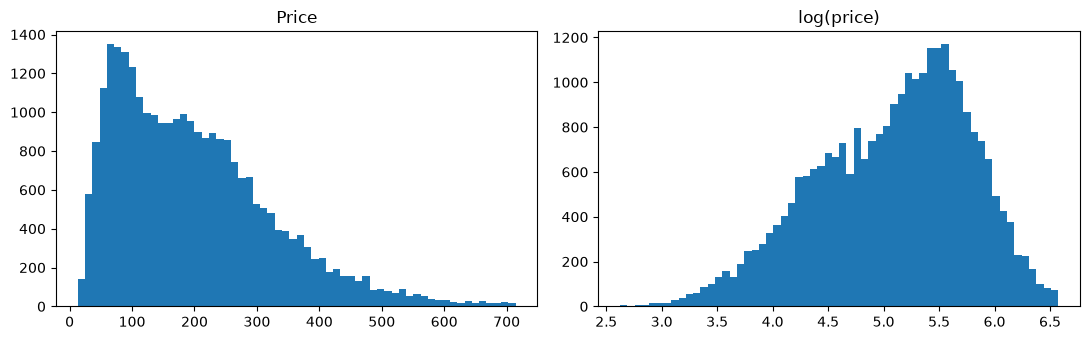

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
d = df.loc[~df.price_missing & ~df.price_outlier, "price"]
ax[0].hist(d, bins=60);           ax[0].set_title("Price")
ax[1].hist(np.log1p(d), bins=60); ax[1].set_title("log(price)")
plt.tight_layout(); plt.show()

In [25]:
bad = (df["price_missing"].astype(bool)
       | df["price_outlier"].astype(bool)
       | df["min_nights_outlier"].astype(bool))

print(f"before: {len(df):,} row")
print(f"delete: {bad.sum():,} row")
df = df[~bad].copy()
print(f"after: {len(df):,} row")

before: 41,183 row
delete: 13,291 row
after: 27,892 row


In [26]:
# --- amenities ---
def count_amenities(s):
    try:
        return len(json.loads(s))
    except Exception:
        return 0

am_raw = df["amenities"].fillna("[]")
am = am_raw.str.lower()

df["n_amenities"] = am_raw.apply(count_amenities)

key_amenities = {
    "has_wifi": "wifi",
    "has_kitchen": "kitchen",
    "has_ac": "air conditioning",
    "has_pool": "pool",
    "has_parking": "parking",
    "has_washer": "washer",
    "has_tv": "tv",
    "has_heating": "heating",
    "has_elevator": "elevator",
}
for col, kw in key_amenities.items():
    df[col] = am.str.contains(kw, regex=False).astype(int)

df[["n_amenities"] + list(key_amenities)].describe().loc[["mean", "min", "max"]].round(2)

,n_amenities,has_wifi,has_kitchen,has_ac,has_pool,has_parking,has_washer,has_tv,has_heating,has_elevator
mean,31.35,0.98,0.87,0.47,0.04,0.52,0.81,0.81,0.86,0.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,99.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [27]:
# --- property_type: top 10 only ---
top_types = df["property_type"].value_counts().head(10).index
df["property_type"] = df["property_type"].where(df["property_type"].isin(top_types), "Other")
print(df["property_type"].value_counts())

property_type
Entire rental unit                   14938
Private room in rental unit           3355
Other                                 2264
Entire home                           1703
Entire condo                          1469
Room in hotel                         1431
Entire serviced apartment              813
Private room in home                   678
Entire loft                            440
Private room in condo                  401
Private room in bed and breakfast      400
Name: count, dtype: int64


In [28]:
# --- Dates → number of days ---
ref_date = df["last_scraped"].max()
df["days_since_last_review"] = (ref_date - df["last_review"]).dt.days
df["listing_age_days"]       = (ref_date - df["first_review"]).dt.days

# --- Neighbourhood + city ---
df["nbh_key"] = df["city"] + " | " + df["neighbourhood_cleansed"].fillna("unknown")

# --- True/False → 0/1 ---
bool_cols = ["host_is_superhost", "host_identity_verified", "has_license",
             "bathroom_shared", "has_reviews"]
for c in bool_cols:
    df[c] = df[c].fillna(False).astype(int)

In [29]:
TARGET = "price"
GROUP  = "host_id"

num_features = [
    # Location
    "latitude", "longitude", "dist_center_km", "dist_nearest_landmark_km",
    "landmarks_1km", "landmarks_2km",
    # Specifications
    "accommodates", "bedrooms", "beds", "bathrooms", "bathroom_shared", "has_license",
    "n_amenities", *key_amenities.keys(),
    # Host
    "host_is_superhost", "host_identity_verified", "host_tenure_years",
    "calculated_host_listings_count",
    # Activity and availability
    "availability_30", "availability_365", "minimum_nights_avg_ntm",
    "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "has_reviews", "days_since_last_review", "listing_age_days",
    # Reviews
    "review_scores_rating", "review_scores_location",
    "review_scores_cleanliness", "review_scores_value",
]
cat_onehot = ["city", "room_type", "property_type"]
cat_target = ["nbh_key"]

model_df = df[[GROUP, TARGET] + num_features + cat_onehot + cat_target].copy()

dropped = sorted(set(df.columns) - set(model_df.columns))
print(f"Columns kept: {model_df.shape[1]}  |  Columns dropped: {len(dropped)}")

Columns kept: 45  |  Columns dropped: 50


In [30]:
model_df["log_price"] = np.log1p(model_df[TARGET])
model_df[[TARGET, "log_price"]].describe().round(2)

,price,log_price
count,27892.00,27892.00
mean,199.02,5.08
std,125.35,0.69
min,12.81,2.63
25%,97.00,4.58
50%,177.68,5.19
75%,270.33,5.60
max,714.33,6.57


In [31]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(model_df, groups=model_df[GROUP]))

train = model_df.iloc[train_idx].copy()
test  = model_df.iloc[test_idx].copy()

print(f"Train: {len(train):,} rows  |  Test: {len(test):,} rows")
print("Hosts shared between train and test:", len(set(train[GROUP]) & set(test[GROUP])))

Train: 22,934 rows  |  Test: 4,958 rows
Hosts shared between train and test: 0


In [32]:
def fill_with_group_median(train, test, col, by):
    med = train.groupby(by)[col].median().rename("_m").reset_index()
    overall = train[col].median()
    for d in (train, test):
        m = d[by].merge(med, on=by, how="left")["_m"].values
        d[col] = d[col].fillna(pd.Series(m, index=d.index)).fillna(overall)

for c in ["bedrooms", "beds"]:
    fill_with_group_median(train, test, c, by=["room_type", "accommodates"])

for d in (train, test):
    d["reviews_per_month"] = d["reviews_per_month"].fillna(0)

# Any other missing value in numeric columns → train median
for c in num_features:
    med = train[c].median()
    train[c] = train[c].fillna(med)
    test[c]  = test[c].fillna(med)

print("missing values in train : ", int(train[num_features].isna().sum().sum()))
print("missing values in test : ", int(test[num_features].isna().sum().sum()))

missing values in train :  0
missing values in test :  0


In [33]:
def smoothed_mean(y, cat, prior, m=20):
    stats = y.groupby(cat).agg(["mean", "count"])
    return (stats["count"] * stats["mean"] + m * prior) / (stats["count"] + m)

col = "nbh_key"
global_mean = train["log_price"].mean()

# Train: out-of-fold
train["nbh_te"] = np.nan
gkf = GroupKFold(n_splits=5)
loc = train.columns.get_loc("nbh_te")
for tr, val in gkf.split(train, groups=train[GROUP]):
    enc = smoothed_mean(train.iloc[tr]["log_price"], train.iloc[tr][col], global_mean)
    train.iloc[val, loc] = train.iloc[val][col].map(enc).fillna(global_mean).values

# Test: from the whole train set
enc_full = smoothed_mean(train["log_price"], train[col], global_mean)
test["nbh_te"] = test[col].map(enc_full).fillna(global_mean)

print("Neighbourhoods in test not found in train:", int((~test[col].isin(train[col])).sum()), "rows")

Neighbourhoods in test not found in train: 3 rows


In [34]:
city_test = test["city"].values   # we need it in the evaluation

feature_cols = num_features + ["nbh_te"]

X_train = pd.get_dummies(train[feature_cols + cat_onehot], columns=cat_onehot, dtype=int)
X_test  = pd.get_dummies(test[feature_cols + cat_onehot],  columns=cat_onehot, dtype=int)
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train, y_test = train["log_price"], test["log_price"]

print("X_train:", X_train.shape, " X_test:", X_test.shape)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

X_train: (22934, 59)  X_test: (4958, 59)


In [35]:


# Small validation set from train (split by host) for early stopping
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
fit_idx, val_idx = next(gss2.split(X_train, groups=train[GROUP]))

xgb = XGBRegressor(
    n_estimators=3000,          # max number of trees (early stopping will stop before it)
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,              # each tree sees 80% of the rows
    colsample_bytree=0.8,       # and each tree sees 80% of the columns
    reg_lambda=1.0,             # L2 penalty like Ridge
    tree_method="hist",         # fastest method
    early_stopping_rounds=50,   # stop if there is no improvement for 50 trees in a row
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

xgb.fit(
    X_train.iloc[fit_idx], y_train.iloc[fit_idx],
    eval_set=[(X_train.iloc[val_idx], y_train.iloc[val_idx])],
    verbose=False,
)
print("Best number of trees:", xgb.best_iteration)

Best number of trees: 439


In [36]:
# ---------- Randomized Search: RandomForest ----------

cv = GroupKFold(n_splits=3)            # split by host so no host is in both train and validation
groups_train = train[GROUP].values
N_ITER = 15                            # number of random combinations to try for each model

rf_grid = {
    "max_depth":        [None, 20],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features":     [0.2, 0.33, 0.5, 0.8],
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),  # 100 trees only during search
    rf_grid, n_iter=N_ITER, cv=cv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, verbose=1,
)
rf_search.fit(X_train, y_train, groups=groups_train)

rf_best = rf_search.best_params_
print("RandomForest best params:", rf_best)
print(f"CV MAE (log price): {-rf_search.best_score_:.4f}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
RandomForest best params: {'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}
CV MAE (log price): 0.2350


In [37]:
# ---------- Randomized Search: HistGradientBoosting ----------
hgb_grid = {
    "learning_rate":    [0.01, 0.02, 0.03, 0.05, 0.08],
    "max_depth":        [None, 6, 10, 14],
    "min_samples_leaf": [20, 50, 80],
}
hgb_search = RandomizedSearchCV(
    HistGradientBoostingRegressor(max_iter=600, early_stopping=True, random_state=RANDOM_STATE),
    hgb_grid, n_iter=N_ITER, cv=cv, scoring="neg_mean_absolute_error",
    n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)
hgb_search.fit(X_train, y_train, groups=groups_train)

hgb_best = hgb_search.best_params_
print("HistGradientBoosting best params:", hgb_best)
print(f"CV MAE (log price): {-hgb_search.best_score_:.4f}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
HistGradientBoosting best params: {'min_samples_leaf': 50, 'max_depth': 10, 'learning_rate': 0.03}
CV MAE (log price): 0.2292


In [38]:
# ---------- Randomized Search: XGBoost ----------
xgb_grid = {
    "learning_rate":    [0.02, 0.03, 0.05, 0.08],
    "max_depth":        [4, 5, 6, 7, 8],
    "min_child_weight": [1, 2, 3, 5],
}
xgb_search = RandomizedSearchCV(
    XGBRegressor(n_estimators=650, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
    xgb_grid, n_iter=N_ITER, cv=cv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, verbose=1,
)
xgb_search.fit(X_train, y_train, groups=groups_train)

xgb_best = xgb_search.best_params_
print("XGBoost best params:", xgb_best)
print(f"CV MAE (log price): {-xgb_search.best_score_:.4f}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
XGBoost best params: {'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.02}
CV MAE (log price): 0.2254


In [39]:
models = {
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "RandomForest": RandomForestRegressor(
        n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **rf_best),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=600, early_stopping=True, random_state=RANDOM_STATE, **hgb_best),
    "xgb": XGBRegressor(
        n_estimators=615,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
        **xgb_best,
    ),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print("Trained:", name)

Trained: LinearRegression
Trained: Ridge
Trained: RandomForest
Trained: HistGradientBoosting
Trained: xgb


In [40]:
y_true = np.expm1(y_test)

rows, preds = [], {}
for name, m in models.items():
    p = np.expm1(m.predict(X_test))
    preds[name] = p
    rows.append({
        "model": name,
        "MAE":  mean_absolute_error(y_true, p),
        "RMSE": root_mean_squared_error(y_true, p),
        "R2":   r2_score(y_true, p),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,MAE,RMSE,R2
model,,,
LinearRegression,54.883,76.815,0.617
Ridge,54.908,76.838,0.617
RandomForest,43.684,64.065,0.734
HistGradientBoosting,41.667,61.376,0.756
xgb,41.364,60.914,0.759


Best model: xgb


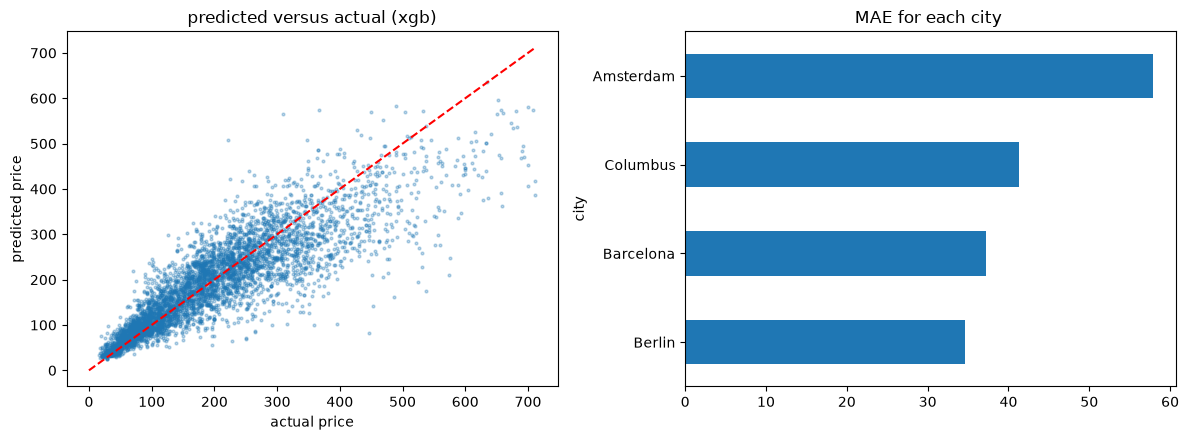

In [41]:
best_name = results["MAE"].idxmin()
best_pred = preds[best_name]
print("Best model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Predicted vs actual
ax[0].scatter(y_true, best_pred, s=4, alpha=0.3)
lim = [0, max(y_true.max(), best_pred.max())]
ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("actual price"); ax[0].set_ylabel("predicted price")
ax[0].set_title(f"predicted versus actual ({best_name})")

# Error for each city
err = pd.DataFrame({"city": city_test, "abs_err": np.abs(y_true.values - best_pred)})
err.groupby("city")["abs_err"].mean().sort_values().plot.barh(ax=ax[1])
ax[1].set_title("MAE for each city ")
plt.tight_layout(); plt.show()

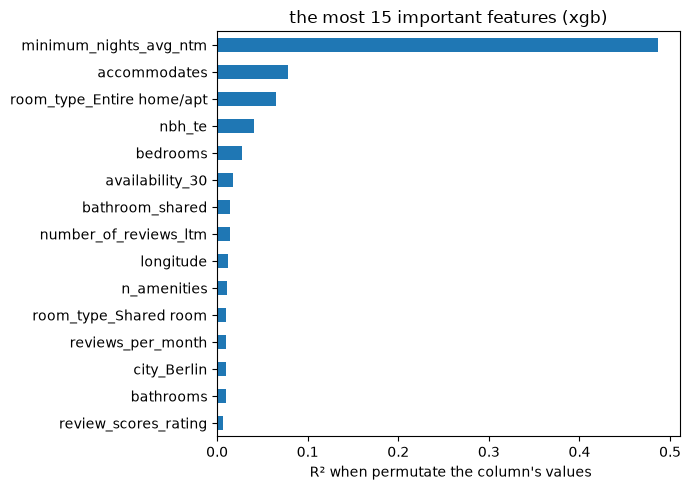

In [42]:
best_model = models[best_name]
imp = permutation_importance(
    best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)

imp_s.head(15)[::-1].plot.barh(figsize=(7, 5))
plt.title(f"the most 15 important features ({best_name})")
plt.xlabel(" R² when permutate the column's values")
plt.tight_layout(); plt.show()

## 7. Evaluation Metrics and Model Comparison

All models are evaluated on the same held-out test set (split by `host_id`, so no host appears in both train and test). Predictions are converted back from log-price to the original price scale before computing the metrics.

- **MAE**: average absolute error in price units (easy to interpret).
- **RMSE**: like MAE but penalises large errors more.
- **R²**: share of price variance explained by the model.

The per-city table below shows the MAE of each model in each city.

In [43]:
# MAE for each model in each city (shows where the models struggle)
city_mae = pd.DataFrame({
    name: pd.Series(np.abs(y_true.values - p)).groupby(city_test).mean()
    for name, p in preds.items()
}).round(2)
city_mae

,LinearRegression,Ridge,RandomForest,HistGradientBoosting,xgb
Amsterdam,72.90,73.13,62.14,58.76,57.88
Barcelona,56.28,56.25,39.01,37.19,37.17
Berlin,40.06,40.07,36.20,34.85,34.67
Columbus,53.86,53.64,43.54,41.83,41.26


## Model Selection Rationale

**Chosen model: XGBoost.**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| LinearRegression | 54.88 | 76.82 | 0.617 |
| Ridge | 54.91 | 76.84 | 0.617 |
| RandomForest | 43.71 | 64.17 | 0.733 |
| HistGradientBoosting | 41.67 | 61.38 | 0.756 |
| **XGBoost** | **41.31** | **60.82** | **0.760** |

- **Tree-based models clearly beat the linear ones** (MAE about 41-44 vs about 55, R² about 0.73-0.76 vs 0.62). The relationship between the features and the price is non-linear, which the linear models cannot capture.
- **Linear Regression and Ridge perform almost the same**, so regularisation does not help here: there are many rows and relatively few features, so overfitting is not the problem.
- **XGBoost has the lowest MAE and RMSE and the highest R²** overall, and it is best or tied-best in most cities (see the per-city MAE table above).
- The gap between XGBoost and HistGradientBoosting is small (about 0.36 in MAE), so both are reasonable choices. XGBoost was selected because it is best on every overall metric.
- It also had the best cross-validated MAE during hyperparameter search (see the printed CV scores of the three search cells above).
- Hyperparameters were chosen with randomized search and 3-fold `GroupKFold` (grouped by host) on the training set only, so the test set was never used for tuning. Tuning had little effect on test performance, which suggests the models are close to the ceiling of the current features.

## Limitations

1. **Missing information about the listing.** The model only sees structured data. Photo quality, the listing title/description text, the real condition of the property and host reputation signals beyond reviews are not used, yet they affect the price guests are charged.
2. **Host-set prices are partly subjective.** Two almost identical listings in the same area can have noticeably different prices only because of the host's pricing strategy, which no feature can explain. This puts a natural ceiling on R².
3. **No time dimension.** The data is a single snapshot (one scrape date). Seasonality, holidays, events and dynamic pricing are not modelled, so the model predicts a typical nightly price, not the price for a specific date.
4. **Rows removed from the data.** Listings with missing prices, price outliers and minimum-night outliers (about 13,000 of 41,000 rows) were removed. The model is therefore not suited for very expensive luxury listings or long-term rentals.
5. **Uneven performance across cities.** Error differs clearly by city: for XGBoost the MAE is about 57 in Amsterdam, 41.8 in Columbus, 37 in Barcelona and 35 in Berlin. The cities have different price levels (Amsterdam listings are the most expensive on average) and different amounts of data (Columbus has far fewer listings than Barcelona), so a single model does not fit all cities equally well.
6. **Errors are larger in absolute terms for expensive listings**, which is visible in RMSE being much higher than MAE.
7. **Non-exhaustive hyperparameter search.** Randomized search (15 random combinations per model, 3-fold grouped cross-validation) was used instead of an exhaustive grid for speed, so slightly better parameter values may exist.
8. **Single train/test split.** Final results come from one split, so small differences between the top models (XGBoost vs HistGradientBoosting) are within normal variation.

In [44]:
EXPORT_DIR = Path("export_for_deployment")
EXPORT_DIR.mkdir(exist_ok=True)

xgb_model = models["xgb"]
xgb_model.save_model(str(EXPORT_DIR / "xgb_model.json"))
train_raw = model_df.loc[train.index]

group_medians = {}
for col in ["bedrooms", "beds"]:
    g = train_raw.groupby(["room_type", "accommodates"])[col].median().dropna()
    group_medians[col] = {f"{rt}|{int(acc)}": float(v) for (rt, acc), v in g.items()}

train_medians = {c: float(train_raw[c].median()) for c in num_features}
assert not any(np.isnan(v) for v in train_medians.values()), "a feature has no values at all"

artifacts = {
    "model_file": "xgb_model.json",
    "feature_columns": X_train.columns.tolist(),   
    "num_features": list(num_features),
    "cat_onehot": list(cat_onehot),
    "key_amenities": dict(key_amenities),
    "top_property_types": [str(t) for t in top_types],
    "train_medians": train_medians,
    "group_medians": group_medians,
    "nbh_encoding": {str(k): float(v) for k, v in enc_full.items()},
    "nbh_global_mean": float(global_mean),
    "reference_date": pd.Timestamp(ref_date).strftime("%Y-%m-%d"),
    "train_price_range": [float(model_df[TARGET].min()), float(model_df[TARGET].max())],
}
(EXPORT_DIR / "artifacts.json").write_text(json.dumps(artifacts, indent=1))

RAW_COLS = [
    "city", "neighbourhood_cleansed", "latitude", "longitude", "room_type", "property_type",
    "accommodates", "bedrooms", "beds", "bathrooms", "bathroom_shared", "has_license",
    "amenities", "host_is_superhost", "host_identity_verified", "host_tenure_years",
    "calculated_host_listings_count", "availability_30", "availability_365",
    "minimum_nights_avg_ntm", "number_of_reviews", "number_of_reviews_ltm",
    "reviews_per_month", "review_scores_rating", "review_scores_location",
    "review_scores_cleanliness", "review_scores_value", "first_review", "last_review",
]
sample_idx = test.sample(min(300, len(test)), random_state=42).index
pos = [test.index.get_loc(i) for i in sample_idx]          
raw = df.loc[sample_idx, RAW_COLS].copy().reset_index(drop=True)
for c in ["first_review", "last_review"]:
    raw[c] = pd.to_datetime(raw[c]).dt.strftime("%Y-%m-%d")
expected_X = X_test.iloc[pos].reset_index(drop=True).add_prefix("X__")
expected_price = pd.Series(np.expm1(xgb_model.predict(X_test.iloc[pos])), name="expected_price")
pd.concat([raw, expected_X, expected_price], axis=1).to_csv(
    EXPORT_DIR / "parity_sample.csv", index=False
)


print("Saved to:", EXPORT_DIR.resolve(), "->", sorted(p.name for p in EXPORT_DIR.iterdir()))
print("room_type values:", sorted(map(str, train["room_type"].unique())))
print("city values:", sorted(map(str, train["city"].unique())))
print("property types (top):", artifacts["top_property_types"])
print("train price range (USD):", artifacts["train_price_range"])
print(df.loc[train.index, ["accommodates", "bedrooms", "beds", "bathrooms", "review_scores_rating",
                           "minimum_nights_avg_ntm", "reviews_per_month"]].describe().loc[["min", "max"]])
print("Next: copy the 3 files into deployment/models/ and also copy landmarks_clean.csv there.")

Saved to: /home/mostafa/Documents/DEPI Project/TravelPulse/machine_learning/export_for_deployment -> ['artifacts.json', 'parity_sample.csv', 'xgb_model.json']
room_type values: ['Entire home/apt', 'Hotel room', 'Private room', 'Shared room']
city values: ['Amsterdam', 'Barcelona', 'Berlin', 'Columbus']
property types (top): ['Entire rental unit', 'Private room in rental unit', 'Entire home', 'Entire condo', 'Room in hotel', 'Entire serviced apartment', 'Private room in home', 'Entire loft', 'Private room in condo', 'Private room in bed and breakfast']
train price range (USD): [12.81, 714.33]
     accommodates  bedrooms   beds  bathrooms  review_scores_rating  \
min           1.0       0.0    1.0        0.0                   0.0   
max          16.0       9.0  127.0       12.0                   5.0   

     minimum_nights_avg_ntm  reviews_per_month  
min                     1.0               0.01  
max                   365.0              76.19  
Next: copy the 3 files into deployment/m

In [1]:
import sys, xgboost, pandas, numpy, sklearn
print(sys.version.split()[0], "xgboost", xgboost.__version__, "pandas", pandas.__version__,
      "numpy", numpy.__version__, "sklearn", sklearn.__version__)

3.15.2 xgboost 3.4.1 pandas 3.1.1 numpy 2.5.5 sklearn 1.9.1
